# Genes Function Analysis

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-09-27
> - Modified: 2025-06-15

# 1. Experimental Design

> Epigenomic comparison of distinct pluripotent stem cell states reveals a new class of enhancers with roles throughout mammalian development.
> - [GSE57409](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE57409)
> - Factor DC, Corradin O, Zentner GE, Saiakhova A, Song L, Chenoweth JG, McKay RD, Crawford GE, Scacheri PC, Tesar PJ. Epigenomic comparison reveals activation of "seed" enhancers during transition from naive to primed pluripotency. Cell Stem Cell. 2014 Jun 5;14(6):854-63. doi: 10.1016/j.stem.2014.05.005.
> - polyA RNA-seq
> - Illumina HiSeq 2000, PE100
> - mm10

| Sample | Organism | Cell | Source | Strain | Treatment | Replicate |
| - | - | - | - | - | - | - |
| mESC | Mus musculus | mESC | Embryionic stem cell | - | - | rep1~4 |
| mEpiSC | Mus musculus | mESC | Epiblast stem cells | - | - | rep1~4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_2/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output"

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 55335    16

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Replicate
,<fct>,<fct>
mESC_rep1,mESC,rep1
mESC_rep2,mESC,rep2
mESC_rep3,mESC,rep3
mESC_rep4,mESC,rep4
mEpiSC_rep1,mEpiSC,rep1
mEpiSC_rep2,mEpiSC,rep2
mEpiSC_rep3,mEpiSC,rep3
mEpiSC_rep4,mEpiSC,rep4


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("rep")) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

In [8]:
keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dds <- dds[keep, ]

Filtered genes summary:
 Pass: 18636 
 Remove: 36699 
 Retention rate: 33.68 %


# 3. DEGs: DESeq2

In [9]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

In [10]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [11]:
degs_result <- lfcShrink(dds, coef = "Cell_mEpiSC_vs_mESC", type = "apeglm") |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




   Up  Down    NS 
  893  1141 16602 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,180.542307,2.4171565,0.8064600,3.200286e-04,1.517455e-03,Up,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,619.595457,5.2737239,0.8311222,1.488993e-11,3.118473e-10,Up,Sox17,protein_coding,4772
ENSMUSG00000098104.1,9.256432,-0.2553383,0.5002902,5.554878e-01,6.900581e-01,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,149.073948,0.3447474,0.4306024,3.762856e-01,5.294105e-01,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,5082.783715,-0.8764312,0.2580623,4.214472e-04,1.931156e-03,NS,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,37.917062,-0.6945105,0.5174921,1.187878e-01,2.232542e-01,NS,Gm37144,TEC,1150


# 4. Functional Enrichment Analysis

In [12]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

## 1). ORA

> Over-Representation Analysis

In [13]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [14]:
degs_result <- add_ENTREZID(
    degs_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“13.18% of input gene IDs are fail to map...”


### a). clusterProfiler

#### GO

In [15]:
genes_up <- degs_result |> filter(result == "Up") |> 
    pull(symbol) |> na.omit() |> unique()
genes_down <- degs_result |> filter(result == "Down") |> 
    pull(symbol) |> na.omit() |> unique()
genes_universe <- degs_result |> 
    pull(symbol) |> na.omit() |> unique()

In [16]:
# GO summary of a set of genes.
ggo <- groupGO(
    gene = genes_up, ont = "BP", level = 3, 
    keyType = 'SYMBOL', OrgDb = org.Mm.eg.db, 
    readable = TRUE)

ggo |> select(-one_of("geneID")) |> arrange(desc(Count)) |> head()

,ID,Description,Count,GeneRatio
,<chr>,<chr>,<int>,<chr>
GO:0050789,GO:0050789,regulation of biological process,568,568/893
GO:0050794,GO:0050794,regulation of cellular process,544,544/893
GO:0048856,GO:0048856,anatomical structure development,433,433/893
GO:0008152,GO:0008152,metabolic process,386,386/893
GO:0007275,GO:0007275,multicellular organism development,377,377/893
GO:0051716,GO:0051716,cellular response to stimulus,375,375/893


In [17]:
# GO enrichment analysis of a gene set.
ego <- enrichGO(
    gene = genes_up, universe = genes_universe, 
    keyType = 'SYMBOL', OrgDb = org.Mm.eg.db, 
    ont = "BP", pAdjustMethod = "BH", 
    pvalueCutoff  = 0.01, qvalueCutoff  = 0.05,
    minGSSize = 10, maxGSSize = 500, 
    readable = TRUE)

ego |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GO:0045165,GO:0045165,cell fate commitment,55/762,255/14379,0.2156863,4.070017,11.700866,1.571948e-19,7.251398e-16,5.154336e-16,55
GO:0072001,GO:0072001,renal system development,62/762,341/14379,0.1818182,3.430923,10.746866,6.238684e-18,1.391611e-14,9.891649e-15,62
GO:0060537,GO:0060537,muscle tissue development,71/762,434/14379,0.1635945,3.087041,10.443654,9.050144e-18,1.391611e-14,9.891649e-15,71
GO:0007389,GO:0007389,pattern specification process,70/762,428/14379,0.1635514,3.086228,10.364944,1.586976e-17,1.830180e-14,1.300903e-14,70
GO:0098742,GO:0098742,cell-cell adhesion via plasma-membrane adhesion molecules,44/762,198/14379,0.2222222,4.193351,10.703155,2.283165e-16,2.106448e-13,1.497276e-13,44
GO:0003002,GO:0003002,regionalization,64/762,389/14379,0.1645244,3.104589,9.954494,3.094006e-16,2.190784e-13,1.557222e-13,64


In [18]:
# drop GO term of specific level or specific terms
ego.subset <- dropGO(ego, level = c(1:4))

ego.subset |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GO:0072001,GO:0072001,renal system development,62/762,341/14379,0.1818182,3.430923,10.746866,6.238684e-18,1.391611e-14,9.891649e-15,62
GO:0060537,GO:0060537,muscle tissue development,71/762,434/14379,0.1635945,3.087041,10.443654,9.050144e-18,1.391611e-14,9.891649e-15,71
GO:0098742,GO:0098742,cell-cell adhesion via plasma-membrane adhesion molecules,44/762,198/14379,0.2222222,4.193351,10.703155,2.283165e-16,2.106448e-13,1.497276e-13,44
GO:0001822,GO:0001822,kidney development,58/762,329/14379,0.1762918,3.326640,10.098921,3.324407e-16,2.190784e-13,1.557222e-13,58
GO:0003007,GO:0003007,heart morphogenesis,51/762,266/14379,0.1917293,3.617947,10.194785,6.296740e-16,3.630858e-13,2.580835e-13,51
GO:0014706,GO:0014706,striated muscle tissue development,65/762,410/14379,0.1585366,2.991598,9.678252,1.169617e-15,5.994937e-13,4.261236e-13,65


In [19]:
# reduce redundancy of enriched GO terms
ego.subset <- simplify(
    ego, cutoff = 0.7, by = "p.adjust", select_fun = min)

ego.subset |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GO:0045165,GO:0045165,cell fate commitment,55/762,255/14379,0.2156863,4.070017,11.70087,1.571948e-19,7.251398e-16,5.154336e-16,55
GO:0072001,GO:0072001,renal system development,62/762,341/14379,0.1818182,3.430923,10.74687,6.238684e-18,1.391611e-14,9.891649e-15,62
GO:0060537,GO:0060537,muscle tissue development,71/762,434/14379,0.1635945,3.087041,10.44365,9.050144e-18,1.391611e-14,9.891649e-15,71
GO:0007389,GO:0007389,pattern specification process,70/762,428/14379,0.1635514,3.086228,10.36494,1.586976e-17,1.830180e-14,1.300903e-14,70
GO:0098742,GO:0098742,cell-cell adhesion via plasma-membrane adhesion molecules,44/762,198/14379,0.2222222,4.193351,10.70315,2.283165e-16,2.106448e-13,1.497276e-13,44
GO:0003007,GO:0003007,heart morphogenesis,51/762,266/14379,0.1917293,3.617947,10.19479,6.296740e-16,3.630858e-13,2.580835e-13,51


In [20]:
multi_ego <- compareCluster(
    geneCluster = list("Up" = genes_up, "Down" = genes_down), 
    fun = enrichGO, universe = genes_universe, 
    keyType = 'SYMBOL', OrgDb = org.Mm.eg.db, 
    ont = "BP", pAdjustMethod = "BH", 
    pvalueCutoff  = 0.01, qvalueCutoff  = 0.05, 
    minGSSize = 10, maxGSSize = 500, 
    readable = TRUE)

multi_ego |> select(-one_of("geneID")) |> head()

,Cluster,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Up,GO:0045165,cell fate commitment,55/762,255/14379,0.2156863,4.070017,11.700866,1.571948e-19,7.251398e-16,5.154336e-16,55
2,Up,GO:0072001,renal system development,62/762,341/14379,0.1818182,3.430923,10.746866,6.238684e-18,1.391611e-14,9.891649e-15,62
3,Up,GO:0060537,muscle tissue development,71/762,434/14379,0.1635945,3.087041,10.443654,9.050144e-18,1.391611e-14,9.891649e-15,71
4,Up,GO:0007389,pattern specification process,70/762,428/14379,0.1635514,3.086228,10.364944,1.586976e-17,1.830180e-14,1.300903e-14,70
5,Up,GO:0098742,cell-cell adhesion via plasma-membrane adhesion molecules,44/762,198/14379,0.2222222,4.193351,10.703155,2.283165e-16,2.106448e-13,1.497276e-13,44
6,Up,GO:0003002,regionalization,64/762,389/14379,0.1645244,3.104589,9.954494,3.094006e-16,2.190784e-13,1.557222e-13,64


#### KEGG

In [21]:
entrez_up <- degs_result |> filter(result == "Up") |> 
    pull(ENTREZID) |> na.omit() |> unique()
entrez_down <- degs_result |> filter(result == "Down") |> 
    pull(ENTREZID) |> na.omit() |> unique()
entrez_universe <- degs_result |> 
    pull(ENTREZID) |> na.omit() |> unique()

In [22]:
ekegg <- enrichKEGG(
    gene = entrez_up, universe = entrez_universe, 
    organism = "mmu", pAdjustMethod = "BH", 
    pvalueCutoff  = 0.01, qvalueCutoff  = 0.05,
    minGSSize = 10, maxGSSize = 500)

ekegg <- setReadable(ekegg, OrgDb = org.Mm.eg.db, keyType = 'ENTREZID')

ekegg |> select(-one_of("geneID")) |> head()

Reading KEGG annotation online: "https://rest.kegg.jp/link/mmu/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/mmu"...



,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
mmu04519,Environmental Information Processing,Signaling molecules and interaction,mmu04519,Cadherin signaling,40/382,296/6590,0.1351351,2.331258,5.813133,3.199168e-07,9.309578e-05,7.846379e-05,40
mmu04514,Environmental Information Processing,Signaling molecules and interaction,mmu04514,Cell adhesion molecule (CAM) interaction,20/382,123/6590,0.1626016,2.805091,5.012631,2.231473e-05,3.246793e-03,2.736490e-03,20
mmu04518,Environmental Information Processing,Signaling molecules and interaction,mmu04518,Integrin signaling,20/382,136/6590,0.1470588,2.536957,4.492440,9.755871e-05,8.000874e-03,6.743366e-03,20
mmu04020,Environmental Information Processing,Signal transduction,mmu04020,Calcium signaling pathway,26/382,204/6590,0.1274510,2.198696,4.313952,1.106306e-04,8.000874e-03,6.743366e-03,26
mmu05414,Human Diseases,Cardiovascular disease,mmu05414,Dilated cardiomyopathy,15/382,88/6590,0.1704545,2.940564,4.545811,1.374721e-04,8.000874e-03,6.743366e-03,15
mmu05202,Human Diseases,Cancer: overview,mmu05202,Transcriptional misregulation in cancer,21/382,154/6590,0.1363636,2.352451,4.212496,1.969843e-04,9.553740e-03,8.052166e-03,21


In [23]:
multi_ekegg <- compareCluster(
    geneCluster = list("Up" = entrez_up, "Down" = entrez_down),
    fun = enrichKEGG, universe = entrez_universe, 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

multi_ekegg <- setReadable(multi_ekegg, OrgDb = org.Mm.eg.db, keyType = 'ENTREZID')

multi_ekegg |> select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Up,Environmental Information Processing,Signaling molecules and interaction,mmu04519,Cadherin signaling,40/382,296/6590,0.1351351,2.331258,5.813133,3.199168e-07,9.309578e-05,7.846379e-05,40
2,Up,Environmental Information Processing,Signaling molecules and interaction,mmu04514,Cell adhesion molecule (CAM) interaction,20/382,123/6590,0.1626016,2.805091,5.012631,2.231473e-05,3.246793e-03,2.736490e-03,20
3,Up,Environmental Information Processing,Signaling molecules and interaction,mmu04518,Integrin signaling,20/382,136/6590,0.1470588,2.536957,4.492440,9.755871e-05,8.000874e-03,6.743366e-03,20
4,Up,Environmental Information Processing,Signal transduction,mmu04020,Calcium signaling pathway,26/382,204/6590,0.1274510,2.198696,4.313952,1.106306e-04,8.000874e-03,6.743366e-03,26
5,Up,Human Diseases,Cardiovascular disease,mmu05414,Dilated cardiomyopathy,15/382,88/6590,0.1704545,2.940564,4.545811,1.374721e-04,8.000874e-03,6.743366e-03,15
6,Up,Human Diseases,Cancer: overview,mmu05202,Transcriptional misregulation in cancer,21/382,154/6590,0.1363636,2.352451,4.212496,1.969843e-04,9.553740e-03,8.052166e-03,21


#### MSigDb

In [24]:
suppressPackageStartupMessages(library(msigdbr))

In [25]:
# Network connection error
term2Gene <- msigdbr(db_species = "MM", species = "mouse") |> 
    dplyr::select(gs_name, gene_symbol)
head(term2Gene)

gs_name,gene_symbol
<chr>,<chr>
ABBUD_LIF_SIGNALING_1_DN,AU021092
ABBUD_LIF_SIGNALING_1_DN,Ahnak
ABBUD_LIF_SIGNALING_1_DN,Alcam
ABBUD_LIF_SIGNALING_1_DN,Ankrd40
ABBUD_LIF_SIGNALING_1_DN,Arid1a
ABBUD_LIF_SIGNALING_1_DN,Bckdhb


In [26]:
emsigdbr <- enricher(
    gene = genes_up, universe = genes_universe, 
    TERM2GENE = term2Gene, pAdjustMethod = "BH", 
    pvalueCutoff  = 0.01, qvalueCutoff  = 0.05,
    minGSSize = 10, maxGSSize = 500)

emsigdbr |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GOCC_EXTERNAL_ENCAPSULATING_STRUCTURE,GOCC_EXTERNAL_ENCAPSULATING_STRUCTURE,GOCC_EXTERNAL_ENCAPSULATING_STRUCTURE,72/848,402/16986,0.1791045,3.587581,12.03561,1.206075e-21,1.089206e-17,8.398091e-18,72
GOBP_RENAL_SYSTEM_DEVELOPMENT,GOBP_RENAL_SYSTEM_DEVELOPMENT,GOBP_RENAL_SYSTEM_DEVELOPMENT,62/848,338/16986,0.1834320,3.674263,11.38380,2.574189e-19,1.162375e-15,8.962242e-16,62
GOBP_MUSCLE_TISSUE_DEVELOPMENT,GOBP_MUSCLE_TISSUE_DEVELOPMENT,GOBP_MUSCLE_TISSUE_DEVELOPMENT,71/848,433/16986,0.1639723,3.284473,11.03818,4.006284e-19,1.206025e-15,9.298797e-16,71
GOBP_CELL_FATE_COMMITMENT,GOBP_CELL_FATE_COMMITMENT,GOBP_CELL_FATE_COMMITMENT,52/848,249/16986,0.2088353,4.183110,11.59894,6.337496e-19,1.419419e-15,1.094413e-15,52
GOBP_PATTERN_SPECIFICATION_PROCESS,GOBP_PATTERN_SPECIFICATION_PROCESS,GOBP_PATTERN_SPECIFICATION_PROCESS,69/848,417/16986,0.1654676,3.314426,10.96905,7.858594e-19,1.419419e-15,1.094413e-15,69
NABA_MATRISOME_ASSOCIATED,NABA_MATRISOME_ASSOCIATED,NABA_MATRISOME_ASSOCIATED,71/848,441/16986,0.1609977,3.224891,10.85177,1.132709e-18,1.704915e-15,1.314538e-15,71


### b). [mulea](https://github.com/ELTEbioinformatics/mulea)

In [27]:
suppressPackageStartupMessages(library(mulea))

In [32]:
# Reading the mulea GMT file locally

# gmt_url <- "https://github.com/ELTEbioinformatics/GMT_files_for_mulea/GMT_files"
gmt_dir <- "~/reference/Database/geneset/GMT_files_for_mulea/GMT_files"
gmt_file <- file.path(gmt_dir, "Mus_musculus_10090", "GO_All_Mus_musculus_GeneSymbol.gmt")

go_ontology <- read_gmt(gmt_file)

dim(go_ontology)
head(go_ontology)

[1] 20285     3

,ontology_id,ontology_name,list_of_values
,<chr>,<chr>,<I<list>>
1,GO:0000002,mitochondrial genome maintenance,"Endog, D...."
2,GO:0000003,reproduction,"Shcbp1l,...."
3,GO:0000009,"alpha-1,6-mannosyltransferase activity","Alg12, Pigv"
4,GO:0000010,trans-hexaprenyltranstransferase activity,Pdss1
5,GO:0000012,single strand break repair,"Parp1, Aplf"
6,GO:0000014,single-stranded DNA endodeoxyribonuclease activity,Ercc1


In [33]:
genes_up <- degs_result |> filter(result == "Up") |> 
    pull(symbol) |> na.omit() |> unique()
genes_down <- degs_result |> filter(result == "Down") |> 
    pull(symbol) |> na.omit() |> unique()
genes_universe <- degs_result |> 
    pull(symbol) |> na.omit() |> unique()

In [38]:
# Creating the ORA model using the GMT variable
ora_model <- ora(
    gmt = go_ontology, element_names = genes_up, 
    background_element_names = genes_universe, 
    p_value_adjustment_method = "eFDR", 
    number_of_permutations = 10000,
    nthreads = 1, random_seed = 123)

In [40]:
# Running the ORA
ora_results <- run_test(ora_model)

In [41]:
ora_results[ora_results$eFDR < 0.05,] |> head()

,ontology_id,ontology_name,nr_common_with_tested_elements,nr_common_with_background_elements,p_value,eFDR
,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>
2,GO:0000003,reproduction,20,205,2.074787e-03,1.783267e-02
400,GO:0001501,skeletal system development,13,54,1.152136e-06,3.902439e-05
405,GO:0001508,action potential,6,26,1.203581e-03,1.236852e-02
444,GO:0001568,blood vessel development,11,58,8.310762e-05,1.494949e-03
486,GO:0001653,peptide receptor activity,6,23,5.967846e-04,8.052273e-03
488,GO:0001655,urogenital system development,15,68,5.911566e-07,1.891892e-05


## ORA Visualization

In [42]:
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(pathview))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(enrichplot))

### 1). Barplot & Dotplot

Warning message in (function (model, data, ...) :
“Arguments in `...` must be used.
✖ Problematic argument:
• by = "Count"
ℹ Did you misspell an argument name?”


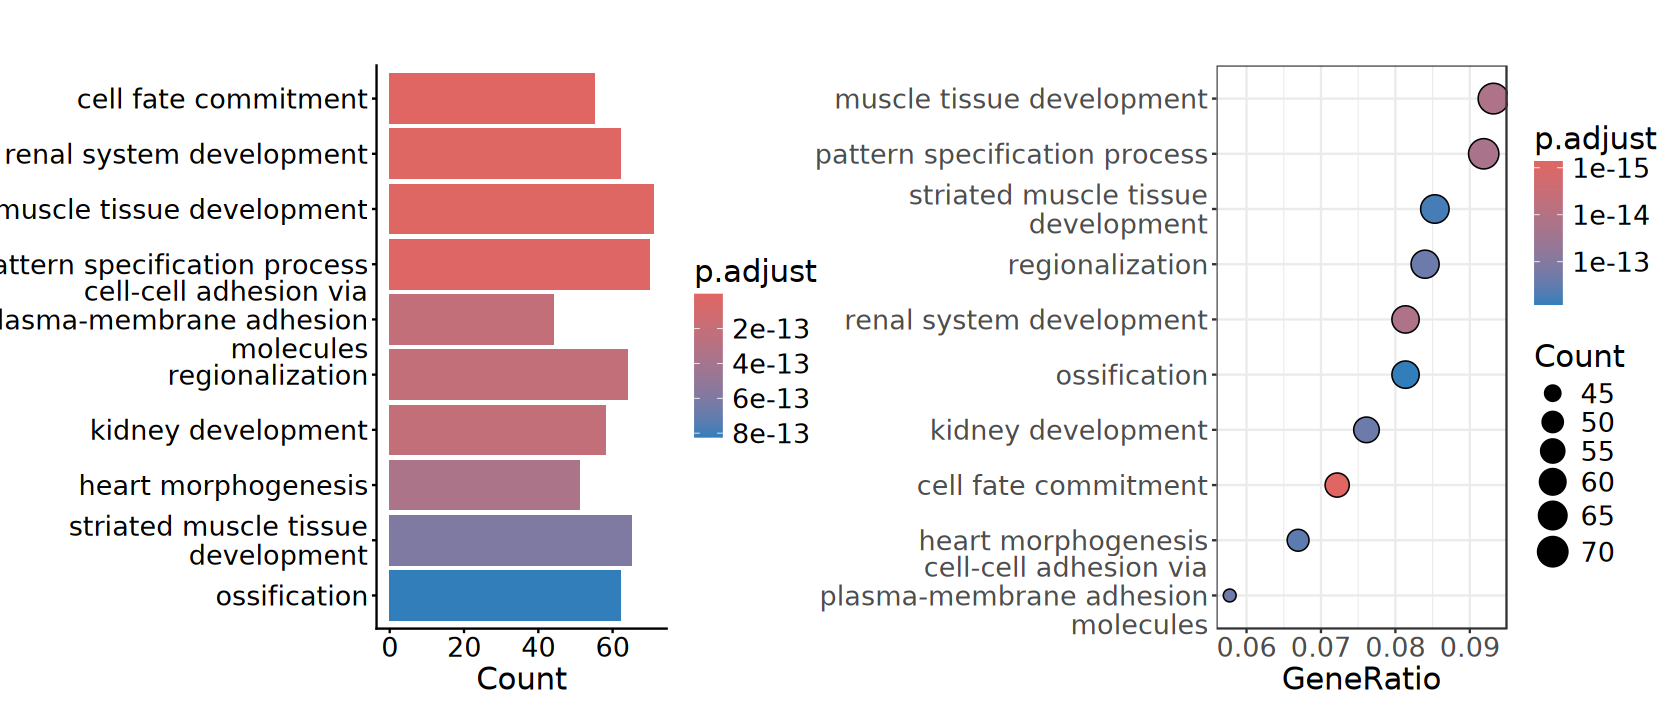

In [44]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 <- barplot(ego, showCategory = 10) + 
    theme_classic() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

p2 <- dotplot(ego, showCategory = 10) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

cowplot::plot_grid(p1, p2, ncol = 2)

In [ ]:
df <- as.data.frame(ego)

df$geneLabel <- apply(df, 1, function(x) {
    selected_genes <- strsplit(x[grep("geneID", colnames(df))], "/")[[1]]
    selected_genes <- intersect(
        degs_result[order(degs_result$logFC),]$gene_name, selected_genes)[1:5]
    paste(paste(selected_genes, collapse = ", "), " ...")
})
head(df, n = 1)

# Reference:

> 1. [Biomedical Knowledge Mining using GOSemSim and clusterProfiler](https://yulab-smu.top/biomedical-knowledge-mining-book).